### Just run it. Script will automatically download the dataset from Github mirror

**How to run**
- Open this notebook in **Google Colab**.
- Runtime → Change runtime type → **GPU** (optional, speeds up the autoencoder).
- Run cells top to bottom (`Runtime → Run all`). No manual upload is needed — the
  dataset is pulled automatically from a public GitHub mirror.


In [ ]:
# Install the libraries
!pip install -q scikit-learn tensorflow matplotlib seaborn pandas


In [ ]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    roc_curve, auc, precision_recall_curve, confusion_matrix,
    precision_score, recall_score, f1_score, accuracy_score
)

import tensorflow as tf
from keras.models import Model
from keras.layers import Input, Dense
from keras.callbacks import EarlyStopping

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
sns.set_style("whitegrid")


## 1. Dataset — UNSW-NB15

UNSW-NB15 is a modern network-traffic dataset from the Australian Centre for
Cyber Security, containing normal traffic plus nine attack categories
(Fuzzers, Analysis, Backdoors, DoS, Exploits, Generic, Reconnaissance,
Shellcode, Worms).

For **anomaly detection** we deliberately don't use the attack labels during
training — we train only on normal connections, then see how well each model
recognises everything else (regardless of attack type) as anomalous.

> If the GitHub mirror below is ever unreachable, download
> `UNSW_NB15_training-set.csv` / `UNSW_NB15_testing-set.csv` from the official
> source (https://research.unsw.edu.au/projects/unsw-nb15-dataset), upload them
> to Colab, and point `TRAIN_URL`/`TEST_URL` at the local file paths instead.


In [ ]:
# Load UNSW-NB15 (train + test partitions), then combine
TRAIN_URL = "https://raw.githubusercontent.com/Nir-J/ML-Projects/master/UNSW-Network_Packet_Classification/UNSW_NB15_training-set.csv"
TEST_URL = "https://raw.githubusercontent.com/Nir-J/ML-Projects/master/UNSW-Network_Packet_Classification/UNSW_NB15_testing-set.csv"

train_raw = pd.read_csv(TRAIN_URL)
test_raw = pd.read_csv(TEST_URL)
full_df = pd.concat([train_raw, test_raw], ignore_index=True)

# Drop identifier column; keep 'label' (0=normal, 1=attack) and 'attack_cat' (attack name)
full_df = full_df.drop(columns=[c for c in ["id"] if c in full_df.columns])

print("Combined shape:", full_df.shape)
print(full_df["label"].value_counts().rename({0: "Normal", 1: "Attack"}))
full_df.head()


Combined shape: (257673, 44)
label
Attack    164673
Normal     93000
Name: count, dtype: int64


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,0.121478,tcp,-,FIN,6,4,258,172,74.087490,252,...,1,1,0,0,0,1,1,0,Normal,0
1,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,62,...,1,2,0,0,0,1,6,0,Normal,0
2,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,62,...,1,3,0,0,0,2,6,0,Normal,0
3,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,62,...,1,3,1,1,0,2,1,0,Normal,0
4,0.449454,tcp,-,FIN,10,6,534,268,33.373826,254,...,1,40,0,0,0,2,39,0,Normal,0


/tmp/ipykernel_1522/2640257523.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=full_df["label"].map({0: "Normal", 1: "Attack"}), palette="Set2")


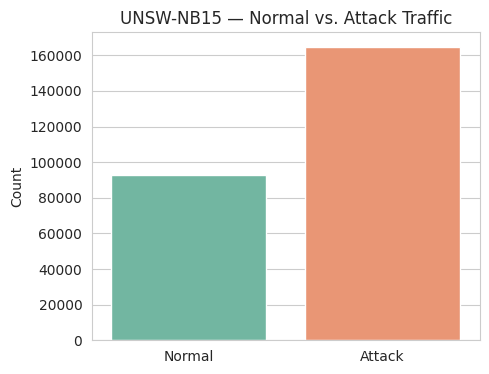

In [ ]:
# Class balance with visualisation
plt.figure(figsize=(5, 4))
sns.countplot(x=full_df["label"].map({0: "Normal", 1: "Attack"}), palette="Set2")
plt.title("UNSW-NB15 — Normal vs. Attack Traffic")
plt.xlabel("")
plt.ylabel("Count")
plt.show()


In [ ]:
# Remove duplicates and split into normal-only training data + mixed evaluation data
full_df = full_df.drop_duplicates().reset_index(drop=True)

normal_df = full_df[full_df["label"] == 0].reset_index(drop=True)
attack_df = full_df[full_df["label"] == 1].reset_index(drop=True)

# 70% of normal traffic -> training (unsupervised, normal-only)
# remaining 30% of normal traffic + ALL attack traffic -> evaluation
normal_train, normal_eval = train_test_split(normal_df, test_size=0.3, random_state=SEED)

eval_df = pd.concat([normal_eval, attack_df], ignore_index=True).sample(frac=1, random_state=SEED)
y_eval = eval_df["label"].values  # 0 = normal, 1 = anomaly/attack

print(f"Training on {len(normal_train)} normal-only connections")
print(f"Evaluating on {len(eval_df)} connections "
      f"({(y_eval == 0).sum()} normal, {(y_eval == 1).sum()} attack)")


Training on 60005 normal-only connections
Evaluating on 102740 connections (25717 normal, 77023 attack)


In [ ]:
# Encode categorical features / scale numeric features
# Fit the preprocessing pipeline on the NORMAL TRAINING data only.
feature_cols = [c for c in full_df.columns if c not in ["label", "attack_cat"]]
categorical_cols = [c for c in ["proto", "service", "state"] if c in feature_cols]
numeric_cols = [c for c in feature_cols if c not in categorical_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ]
)

X_train = preprocessor.fit_transform(normal_train[feature_cols])
X_eval = preprocessor.transform(eval_df[feature_cols])

X_train = np.asarray(X_train.todense()) if hasattr(X_train, "todense") else np.asarray(X_train)
X_eval = np.asarray(X_eval.todense()) if hasattr(X_eval, "todense") else np.asarray(X_eval)

print("X_train:", X_train.shape, " X_eval:", X_eval.shape)


X_train: (60005, 66)  X_eval: (102740, 66)


In [ ]:
# Train Isolation Forest on normal-only traffic
iso_forest = IsolationForest(
    n_estimators=200, contamination="auto", random_state=SEED, n_jobs=-1
)
iso_forest.fit(X_train)

# decision_function: higher = more normal. We flip the sign so higher = more anomalous,
# which keeps the interpretation consistent with the autoencoder's reconstruction error.
iso_scores = -iso_forest.decision_function(X_eval)

print("Isolation Forest anomaly scores computed for the evaluation set.")


Isolation Forest anomaly scores computed for the evaluation set.


In [ ]:
# Build and train the autoencoder on normal-only traffic
input_dim = X_train.shape[1]
encoding_dim = max(8, input_dim // 4)

inputs = Input(shape=(input_dim,))
encoded = Dense(64, activation="relu")(inputs)
encoded = Dense(encoding_dim, activation="relu")(encoded)
decoded = Dense(64, activation="relu")(encoded)
decoded = Dense(input_dim, activation="linear")(decoded)

autoencoder = Model(inputs, decoded)
autoencoder.compile(optimizer="adam", loss="mse")
autoencoder.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 66)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 66)             │         4,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,706 (41.82 KB)

 Trainable params: 10,706 (41.82 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train the autoencoder to reconstruct normal traffic
early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history = autoencoder.fit(
    X_train, X_train,
    validation_split=0.1,
    epochs=25,
    batch_size=256,
    shuffle=True,
    callbacks=[early_stop],
    verbose=1,
)


Epoch 1/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - loss: 0.2854 - val_loss: 0.1463
Epoch 2/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0913 - val_loss: 0.0926
Epoch 3/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0593 - val_loss: 0.0602
Epoch 4/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0411 - val_loss: 0.0405
Epoch 5/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0306 - val_loss: 0.0286
Epoch 6/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0243 - val_loss: 0.0219
Epoch 7/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0203 - val_loss: 0.0184
Epoch 8/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0178 - val_loss: 0.0163
Epoch 9/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0162 - val_loss: 0.0148
Epoch 10/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0149 - val_loss: 0.0137
Epoch 11/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0138 - val_loss: 0.0127
Epoch 12/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/ste

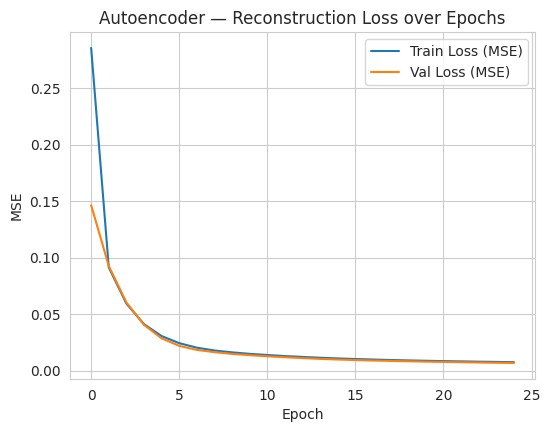

In [ ]:
# Training curve with visualisation
plt.figure(figsize=(6, 4.5))
plt.plot(history.history["loss"], label="Train Loss (MSE)")
plt.plot(history.history["val_loss"], label="Val Loss (MSE)")
plt.title("Autoencoder — Reconstruction Loss over Epochs")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.show()


In [ ]:
# Reconstruction error on the evaluation set = anomaly score
eval_reconstructions = autoencoder.predict(X_eval)
ae_scores = np.mean(np.square(X_eval - eval_reconstructions), axis=1)

print("Autoencoder anomaly scores computed for the evaluation set.")


3211/3211 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step
Autoencoder anomaly scores computed for the evaluation set.


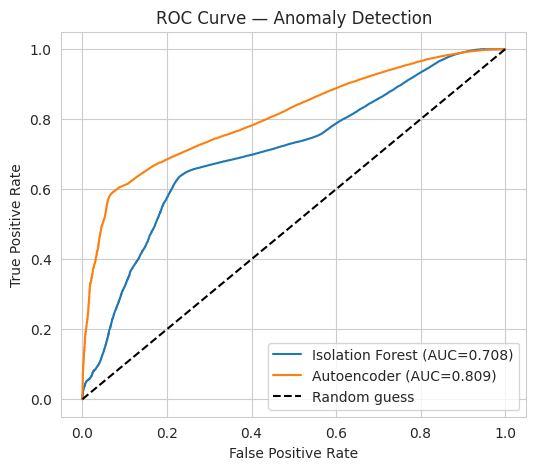

In [ ]:
# ROC curves for both models
fpr_iso, tpr_iso, _ = roc_curve(y_eval, iso_scores)
fpr_ae, tpr_ae, _ = roc_curve(y_eval, ae_scores)
auc_iso = auc(fpr_iso, tpr_iso)
auc_ae = auc(fpr_ae, tpr_ae)

plt.figure(figsize=(6, 5))
plt.plot(fpr_iso, tpr_iso, label=f"Isolation Forest (AUC={auc_iso:.3f})")
plt.plot(fpr_ae, tpr_ae, label=f"Autoencoder (AUC={auc_ae:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Anomaly Detection")
plt.legend(loc="lower right")
plt.show()


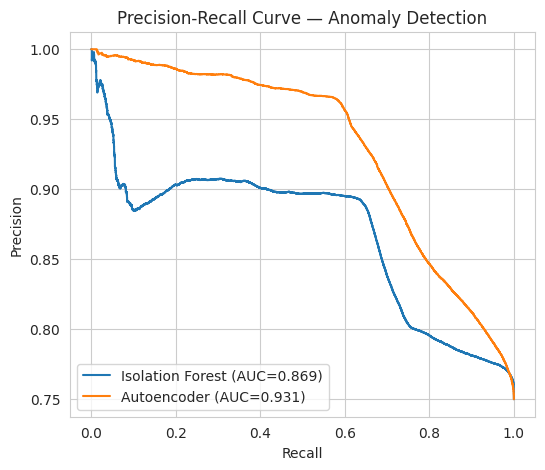

In [ ]:
# Precision-Recall curves for both models
prec_iso, rec_iso, _ = precision_recall_curve(y_eval, iso_scores)
prec_ae, rec_ae, _ = precision_recall_curve(y_eval, ae_scores)

plt.figure(figsize=(6, 5))
plt.plot(rec_iso, prec_iso, label=f"Isolation Forest (AUC={auc(rec_iso, prec_iso):.3f})")
plt.plot(rec_ae, prec_ae, label=f"Autoencoder (AUC={auc(rec_ae, prec_ae):.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve — Anomaly Detection")
plt.legend(loc="lower left")
plt.show()


In [ ]:
# Pick an operating threshold (95th percentile of TRAINING-time normal scores)
# and report TPR/FPR/precision/recall/F1 + confusion matrix at that threshold.
iso_train_scores = -iso_forest.decision_function(X_train)
ae_train_reconstructions = autoencoder.predict(X_train)
ae_train_scores = np.mean(np.square(X_train - ae_train_reconstructions), axis=1)

iso_threshold = np.percentile(iso_train_scores, 95)
ae_threshold = np.percentile(ae_train_scores, 95)

iso_preds = (iso_scores >= iso_threshold).astype(int)
ae_preds = (ae_scores >= ae_threshold).astype(int)

def tpr_fpr(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    tpr = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    return tpr, fpr, cm

iso_tpr, iso_fpr, cm_iso = tpr_fpr(y_eval, iso_preds)
ae_tpr, ae_fpr, cm_ae = tpr_fpr(y_eval, ae_preds)

iso_metrics = {
    "TPR (Recall)": iso_tpr, "FPR": iso_fpr,
    "Precision": precision_score(y_eval, iso_preds),
    "F1-score": f1_score(y_eval, iso_preds),
    "Accuracy": accuracy_score(y_eval, iso_preds),
}
ae_metrics = {
    "TPR (Recall)": ae_tpr, "FPR": ae_fpr,
    "Precision": precision_score(y_eval, ae_preds),
    "F1-score": f1_score(y_eval, ae_preds),
    "Accuracy": accuracy_score(y_eval, ae_preds),
}

print("Isolation Forest @ 95th-percentile threshold:")
for k, v in iso_metrics.items():
    print(f"  {k}: {v:.4f}")
print()
print("Autoencoder @ 95th-percentile threshold:")
for k, v in ae_metrics.items():
    print(f"  {k}: {v:.4f}")


1876/1876 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
Isolation Forest @ 95th-percentile threshold:
  TPR (Recall): 0.1446
  FPR: 0.0523
  Precision: 0.8923
  F1-score: 0.2489
  Accuracy: 0.3456

Autoencoder @ 95th-percentile threshold:
  TPR (Recall): 0.5085
  FPR: 0.0495
  Precision: 0.9685
  F1-score: 0.6669
  Accuracy: 0.6191


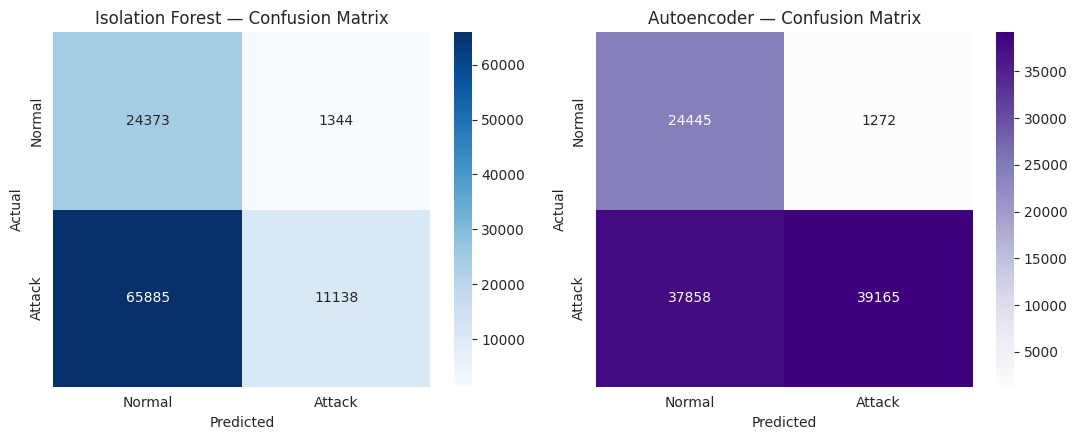

In [ ]:
# Confusion matrices at the chosen threshold
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.heatmap(cm_iso, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"], ax=axes[0])
axes[0].set_title("Isolation Forest — Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(cm_ae, annot=True, fmt="d", cmap="Purples",
            xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"], ax=axes[1])
axes[1].set_title("Autoencoder — Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()


                  TPR (Recall)     FPR  Precision  F1-score  Accuracy
Isolation Forest        0.1446  0.0523     0.8923    0.2489    0.3456
Autoencoder             0.5085  0.0495     0.9685    0.6669    0.6191


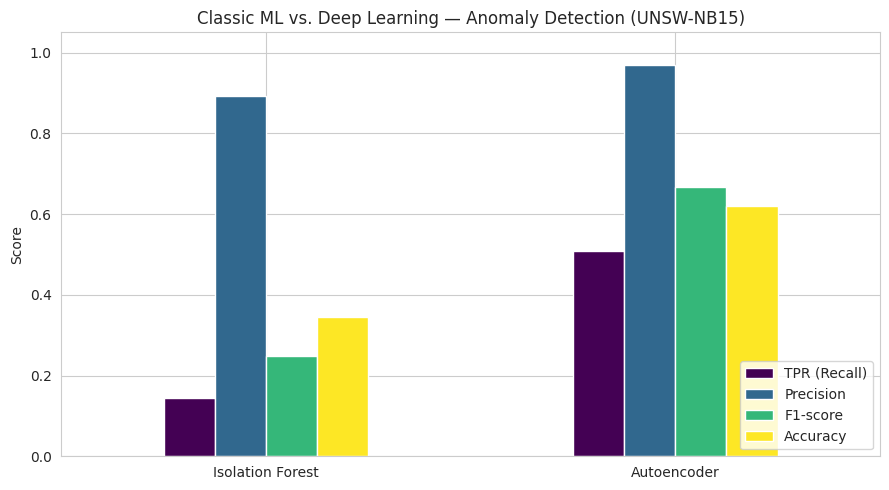

In [ ]:
# comparison table + chart
comparison = pd.DataFrame({
    "Isolation Forest": iso_metrics,
    "Autoencoder": ae_metrics,
}).T

print(comparison.round(4))

comparison[["TPR (Recall)", "Precision", "F1-score", "Accuracy"]].plot(
    kind="bar", figsize=(9, 5), colormap="viridis"
)
plt.title("Classic ML vs. Deep Learning — Anomaly Detection (UNSW-NB15)")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()
